# 3 · A well pair over 30 years: what 16A(78)-32 / 16B(78)-32 could deliver

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, Milford, Utah (USA)**

**Question.** If the FORGE well pair circulated water for 30 years at 10–80 kg/s, what would it produce: temperature, thermal breakthrough, heat power, pressure, and how far would the rock cool? With a P10–P90 for every number, and checked first against the 2024 circulation tests.

**Data.** The extended circulation test of 8 August – 5 September 2024 (GDR 1683, DOI [10.15121/2475065](https://doi.org/10.15121/2475065)): 30-second wellhead pressures, rates and temperature, the field calibration of the flow meters and the manual temperature checks; the 9-hour circulation test of 27 April 2024 (GDR 1611, DOI [10.15121/2371032](https://doi.org/10.15121/2371032)). The fractured-granite ensemble of notebook 2 and the temperature model of notebook 1. *Credit: Utah FORGE, U.S. Department of Energy, via the Geothermal Data Repository (OpenEI), CC BY 4.0.*

**Model.** KAI Reservoir Lab, two-point-flux flow and heat on a 1,050 × 630 × 630 m block of 35 m cells around the open intervals, rotated to the wells' azimuth (105°); water properties follow temperature; heat advection is flux-limited (TVD, van Leer); tight granitoid beyond the block (closed sides; water lost only into storage). Initial temperature and pressure from the FORGE 3-D model (notebook 1). The wells are open over their stimulated intervals (16A from 9,270 ft MD, 16B from 9,240 ft MD, to total depth).

**Labels.** Every model number here is **simulated**; the forecasts are not field data. Breakthrough is the time at which the produced temperature has fallen by 5 % of (initial − reinjection) temperature; reinjection at 60 °C. P10 is the 10th percentile of the members (the low case), P90 the 90th.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, GRANITE, BLUE, GREY = "#c9a227", "#26292e", "#b5838d", "#2a78d6", "#8a8f98"     # KAI energy palette
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase3.json").read_text())      # KAI engine run (simulated)
ens = E["ensemble"]
def pct(d, f="{:.1f}"):
    fm = lambda v: v if isinstance(v, str) else f.format(v)
    return f"{fm(d['P50'])} ({fm(d['P10'])}–{fm(d['P90'])})"
print(E["label"]); print(f"ensemble: {ens['members'] - ens['failed']}/{ens['members']} members ran, {ens['calibration_converged']} calibrated")

simulated (KAI Reservoir Lab TPFA solver, equivalent-continuum fractured granite); not field data
ensemble: 20/20 members ran, 20 calibrated


## The 2024 circulation tests

Daily medians of the 30-second data. Produced mass is the calibrated separator outflow plus the 19.6 % flash fraction (as in the report); the in-line temperature reads low, so the manual temperature-gun offset is added.

In [2]:
daily = pd.read_csv("data/circulation_2024_aug_daily.csv", index_col=0)
S = json.loads(pathlib.Path("data/circulation_2024_summary.json").read_text())
T = E["tests"]["august_2024"]
for k in ("injection_kg_s", "produced_kg_s", "recovery", "whp_16A_mpa", "whp_16B_mpa", "T_16B_wellhead_c"):
    assert abs(S[k] - T[k]) < 1e-5 * max(1, abs(T[k])), k
win = daily.loc[14:25]
assert abs(win.inj_bpm.median() * ft.BBL_L / 60 * float(ft.water_density(25)) / 1000 / S["injection_kg_s"] - 1) < 0.01
print(f"steady 10 bpm (days 14–26): {S['injection_kg_s']:.1f} kg/s in, {S['produced_kg_s']:.1f} kg/s out (recovery {S['recovery']:.0%}); "
      f"wellhead pressure 16A {S['whp_16A_mpa']:.1f} MPa, 16B {S['whp_16B_mpa']:.2f} MPa; produced {S['T_16B_wellhead_c']:.1f} °C at the wellhead")
mb = E["members"][0]["measured_bhp"]
print(f"at the top open cell: injector {mb['injector_bhp_pa'] / 1e6:.1f} MPa (cold column, {mb['friction_mpa'] * 1:.1f} MPa friction), producer {mb['producer_bhp_pa'] / 1e6:.1f} MPa")

steady 10 bpm (days 14–26): 26.5 kg/s in, 24.5 kg/s out (recovery 93%); wellhead pressure 16A 19.6 MPa, 16B 1.73 MPa; produced 189.8 °C at the wellhead
at the top open cell: injector 42.8 MPa (cold column, 0.3 MPa friction), producer 21.9 MPa


## Calibration and validation

Each member is calibrated on one number: the injector bottom-hole pressure after 20 days at 10 bpm. It is then run through the test as it happened (measured daily rates into 16A, 16B at its measured pressure, water and rock compressible) and through the April test. Recovery, produced rate and temperature were **not** fitted.

,quantity,measured,model P50 (P10–P90),fitted
0,injector bottom-hole pressure (MPa),42.800,41.8 (41.4–42.1),yes (steady run)
1,produced rate (kg/s),24.500,24.8 (24.1–25.4),no
2,recovery (out / in),0.926,0.938 (0.909–0.960),no
3,produced temperature (°C): model bottom hole /...,189.800,214.0 (212.6–215.5),no
4,… after an estimated wellbore cooling (Ramey),189.800,202.9 (201.5–204.3),no
5,April: injector wellhead pressure at 13.9 bpm ...,24.300,16.5 (13.8–18.3),no
6,April: produced rate at the end (bpm),8.200,7.7 (3.6–9.0),no


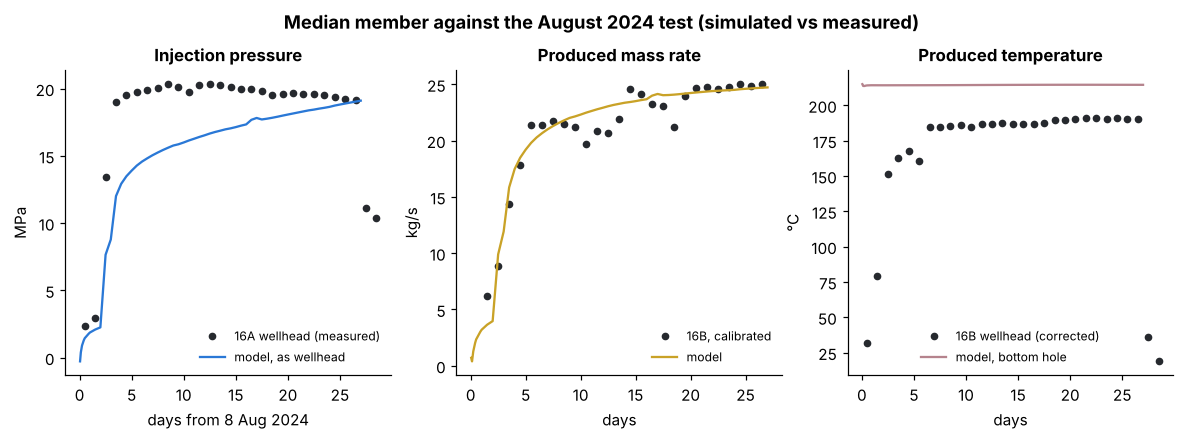

In [3]:
V = ens["validation"]
aug, apr = V["august_2024"], V["april_2024"]
rows = [
    {"quantity": "injector bottom-hole pressure (MPa)", "measured": round(aug["measured_injector_bhp_mpa"]["P50"], 1), "model P50 (P10–P90)": pct(aug["injector_bhp_mpa"]), "fitted": "yes (steady run)"},
    {"quantity": "produced rate (kg/s)", "measured": round(T["produced_kg_s"], 1), "model P50 (P10–P90)": pct(aug["produced_kg_s"]), "fitted": "no"},
    {"quantity": "recovery (out / in)", "measured": round(T["recovery"], 3), "model P50 (P10–P90)": pct(aug["recovery"], "{:.3f}"), "fitted": "no"},
    {"quantity": "produced temperature (°C): model bottom hole / measured wellhead", "measured": round(T["T_16B_wellhead_c"], 1), "model P50 (P10–P90)": pct(aug["produced_T_bottomhole_c"]), "fitted": "no"},
    {"quantity": "… after an estimated wellbore cooling (Ramey)", "measured": round(T["T_16B_wellhead_c"], 1), "model P50 (P10–P90)": pct({k: (aug["produced_T_bottomhole_c"][k] - aug["wellbore_cooling_estimate_c"]["P50"]) if not isinstance(aug["produced_T_bottomhole_c"][k], str) else 0 for k in ("P10", "P50", "P90")}), "fitted": "no"},
    {"quantity": "April: injector wellhead pressure at 13.9 bpm (MPa)", "measured": round(E["tests"]["april_2024"]["final_whp_mpa"], 1), "model P50 (P10–P90)": pct(apr["injector_whp_equivalent_mpa"]), "fitted": "no"},
    {"quantity": "April: produced rate at the end (bpm)", "measured": 8.2, "model P50 (P10–P90)": pct(apr["produced_bpm_end"]), "fitted": "no"},
]
display(pd.DataFrame(rows))
s = E["median_member"]["validation"]["august_2024"]["series"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
dd = daily.index.values + 0.5
ax[0].plot(dd, daily.whp_16A_psi * ft.PSI / 1e6, "o", color=CHARCOAL, ms=4, label="16A wellhead (measured)")
ax[0].plot(s["t_days"], np.array(s["injector_bhp_mpa"]) - (mb["injector_bhp_pa"] / 1e6 - S["whp_16A_mpa"]), color=BLUE, label="model, as wellhead")
ax[0].set_xlabel("days from 8 Aug 2024"); ax[0].set_ylabel("MPa"); ax[0].set_title("Injection pressure"); ax[0].legend(fontsize=8)
prod_d = daily.liquid_gpm_cal * ft.GAL_L / 60 * float(ft.water_density((202.2 - 32) / 1.8)) / 1000 / (1 - ft.STEAM_FRACTION)
ax[1].plot(dd, prod_d, "o", color=CHARCOAL, ms=4, label="16B, calibrated"); ax[1].plot(s["t_days"], s["produced_kg_s"], color=GOLD, label="model")
ax[1].set_xlabel("days"); ax[1].set_ylabel("kg/s"); ax[1].set_title("Produced mass rate"); ax[1].legend(fontsize=8)
ax[2].plot(dd, (daily.T_16B_raw_f - 32) / 1.8 + S["manual_offset_c"], "o", color=CHARCOAL, ms=4, label="16B wellhead (corrected)")
ax[2].plot(s["t_days"], s["produced_T_c"], color=GRANITE, label="model, bottom hole")
ax[2].set_xlabel("days"); ax[2].set_ylabel("°C"); ax[2].set_title("Produced temperature"); ax[2].legend(fontsize=8)
fig.suptitle("Median member against the August 2024 test (simulated vs measured)", y=1.03, fontweight="bold")
fig.savefig("figures/forge_validation_2024.png")

**Reading the misfit.** The injection pressure is fitted at the end of the test, so its agreement there is not a test. Its build-up is: the model reaches the measured pressure more slowly (2–5 MPa low between days 4 and 15), so its storage is too large or its early permeability too high; in the field the pressure rose to near the minimum horizontal stress within a day of the step to 10 bpm. The recovery is a test: the model loses water only into the storage of the fractured rock (fracture compressibility from the 2024 DFN), and that alone gives a recovery close to the measured one. The produced temperature is not reproduced: the model's bottom-hole temperature is well above the corrected wellhead temperature, and a simple wellbore heat-loss estimate explains less than half of the gap. Either the fluid comes from cooler (shallower) paths than the model's, or the FORGE temperature model is too hot at 16B, or the wellbore loses more heat than the estimate. The April injection pressure is not reproduced either: the model needs about 8 MPa less than was measured at 13.9 bpm, although its produced rate at the end (7.7 bpm, P10–P90 3.6–9.0) brackets the measured 8.2 bpm. In April the stimulated fractures had just been drained during the plug drill-out and were refilling (the report says so); the model starts from undisturbed pressure and its fracture apertures do not depend on pressure.

## Thirty years at 10–80 kg/s

Injection equals production; 60 °C reinjection. A rate is **pressure-feasible** in a member when the injector stays below the minimum horizontal stress (17 kPa/m, GDR 1222) and the producer stays at least 1 MPa above the saturation pressure. The model does not create new fractures, so above about twice the 2024 rate the thermal results describe flow paths that the present stimulation cannot drive: they are what the rock could give if circulation at that rate were possible.

,rate (kg/s),"produced T, year 1 (°C)",year 10 (°C),year 30 (°C),breakthrough (years),"heat, year 1 (MWth)","heat, year 30 (MWth)",injector BHP max / Shmin,producer BHP min (MPa),cooled > 10 °C at 30 y (Mm³),feasible members
0,10,213.7 (212.4–215.4),160.5 (138.0–178.9),130.4 (116.4–147.7),1.78 (0.91–2.61),6.4 (6.1–6.6),2.9 (2.4–3.7),0.69 (0.62–0.75),10.6 (8.3–12.8),31.8 (27.4–35.7),20/20
1,20,213.7 (212.4–215.4),136.2 (118.2–158.1),108.0 (99.6–126.0),0.85 (0.43–1.27),12.1 (11.0–12.6),4.0 (3.3–5.5),0.89 (0.75–1.03),-2.1 (-6.9–1.8),45.8 (37.8–52.3),0/20
2,40,213.7 (212.4–215.4),112.3 (102.0–137.0),90.8 (87.1–107.9),0.40 (0.21–0.60),21.3 (17.8–23.5),5.1 (4.5–8.0),1.33 (1.06–1.61),-28.6 (-39.0–-22.5),63.2 (52.0–76.1),0/20
3,60,213.7 (212.4–215.4),100.5 (94.5–125.0),83.3 (80.4–99.6),0.27 (0.14–0.39),28.5 (22.2–33.0),5.8 (5.1–9.9),1.77 (1.40–2.20),-58.3 (-72.4–-47.9),74.9 (61.8–92.8),0/20
4,80,213.8 (212.4–215.4),93.7 (88.4–117.1),79.5 (76.7–94.5),0.20 (0.11–0.29),34.6 (25.8–41.6),6.5 (5.6–11.5),2.22 (1.75–2.79),-89.7 (-106.4–-73.8),83.5 (69.8–107.4),0/20


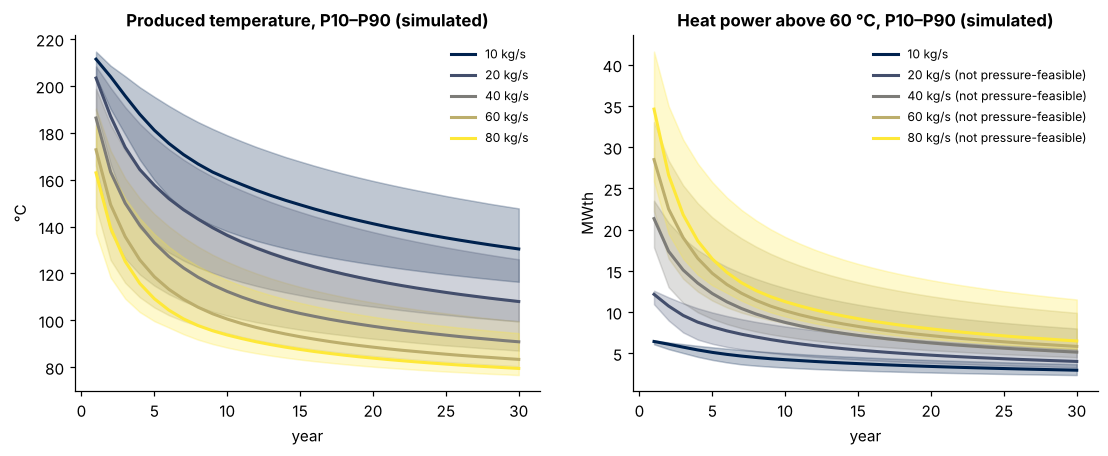

In [4]:
R = ens["rates"]
rows = []
for q, r in R.items():
    sc = r["scalars"]
    rows.append({"rate (kg/s)": int(q), "produced T, year 1 (°C)": pct(sc["T_prod_initial_c"]), "year 10 (°C)": pct(sc["T_prod_10y_c"]),
                 "year 30 (°C)": pct(sc["T_prod_end_c"]), "breakthrough (years)": pct(sc["breakthrough_years"], "{:.2f}"),
                 "heat, year 1 (MWth)": pct(sc["power_initial_mw"]), "heat, year 30 (MWth)": pct(sc["power_end_mw"]),
                 "injector BHP max / Shmin": pct(sc["injector_bhp_over_shmin"], "{:.2f}"), "producer BHP min (MPa)": pct(sc["producer_bhp_min_mpa"]),
                 "cooled > 10 °C at 30 y (Mm³)": pct(sc["cooled_volume_30y_mm3"]), "feasible members": f"{r['feasible_members']}/{ens['members'] - ens['failed']}"})
tab = pd.DataFrame(rows); display(tab)
tab.to_csv("results/nb3_forecast_table.csv", index=False)
yrs = np.arange(1, 31)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
cmap = plt.get_cmap("cividis")
for i, (q, r) in enumerate(R.items()):
    c = cmap(i / (len(R) - 1)); s_ = r["series"]["T_prod_yearly_c"]
    ax[0].fill_between(yrs, s_["P10"], s_["P90"], color=c, alpha=0.25); ax[0].plot(yrs, s_["P50"], color=c, lw=2, label=f"{q} kg/s")
    p_ = r["series"]["power_yearly_mw"]
    ax[1].fill_between(yrs, p_["P10"], p_["P90"], color=c, alpha=0.25); ax[1].plot(yrs, p_["P50"], color=c, lw=2, label=f"{q} kg/s" + ("" if r["feasible_members"] else " (not pressure-feasible)"))
ax[0].set_xlabel("year"); ax[0].set_ylabel("°C"); ax[0].set_title("Produced temperature, P10–P90 (simulated)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("year"); ax[1].set_ylabel("MWth"); ax[1].set_title("Heat power above 60 °C, P10–P90 (simulated)"); ax[1].legend(fontsize=8)
fig.savefig("figures/forge_30_years.png")

## How much the breakthrough time depends on the grid

Breakthrough is quoted as the grid-converged value with its discretisation error. The median member is rebuilt and recalibrated at 52.5, 35 and 23.3 m cells; Richardson extrapolation gives the converged value and the grid convergence index (GCI) its error. The solver itself is checked the same way on a doublet with an exact answer and against open-DARTS (second table, from the KAI engine's validation suite).

Here the finer grids give *earlier* breakthrough, the opposite of the doublet: finer cells resolve narrower fracture channels, so the change is mostly in how the fractures map to cells, not numerical dispersion. The observed order is above the scheme's formal order, so the coarsest grid is outside the asymptotic range and the GCI should be read as a lower bound. The 35 m ensemble overestimates breakthrough by about 25 % at 10 kg/s and 40 % at 40 kg/s.

In [5]:
G = E["grid_convergence"]
rows = []
for q, g in G["rates"].items():
    b = g["breakthrough_years"]
    rows.append({"rate (kg/s)": int(q), **{f"{r['cell_m']:.1f} m": round(r["breakthrough_years"], 3) for r in g["runs"]},
                 "converged ± GCI (years)": f"{b['converged']:.3f} ± {b['error_abs']:.3f}", "observed order": None if b["order"] is None else round(b["order"], 2),
                 "35 m vs converged": f"{g['runs'][1]['breakthrough_years'] / b['converged'] - 1:+.1%}"})
display(pd.DataFrame(rows))
C = E["solver_convergence"]
rows = []
for part, lab in (("dipole", "doublet with exact answer"), ("closed", "closed box")):
    for k, d in C[part]["schemes"].items():
        rr = d["richardson"]
        rows.append({"case": lab, "scheme": k, **{f"{x['cell_m']:.0f} m": round(x["breakthrough_years"], 3) for x in d["runs"]},
                     "converged ± GCI": f"{rr['converged']:.3f} ± {rr['error_abs']:.3f}"})
display(pd.DataFrame(rows)); print(f"exact: {C['dipole']['exact_years']:.3f} years")

,rate (kg/s),52.5 m,35.0 m,23.3 m,converged ± GCI (years),observed order,35 m vs converged
0,10,2.707,1.687,1.433,1.348 ± 0.105,3.43,+25.1%
1,40,0.636,0.393,0.316,0.280 ± 0.045,2.83,+40.4%


,case,scheme,40 m,20 m,10 m,5 m,converged ± GCI
0,doublet with exact answer,upwind,3.119,3.538,3.839,4.031,4.366 ± 0.419
1,doublet with exact answer,tvd_minmod,3.696,3.986,4.143,4.224,4.311 ± 0.108
2,doublet with exact answer,tvd_van_leer,3.815,4.046,4.179,4.245,4.310 ± 0.081
3,closed box,upwind,2.765,3.133,3.411,3.591,3.919 ± 0.409
4,closed box,tvd_van_leer,3.424,3.619,3.743,3.806,3.871 ± 0.081
5,closed box,open_darts,2.802,3.175,3.424,3.586,3.882 ± 0.370


exact: 4.277 years


## The cooling front

Temperature on a vertical section along the wells, median member at 40 kg/s, after 1, 10 and 30 years (simulated).

cooled by more than 10 °C at 40 kg/s: 29.6 (23.8–34.5) Mm³ after 10 years, 63.2 (52.0–76.1) Mm³ after 30 years; reach from the injector 317 (245–330) m


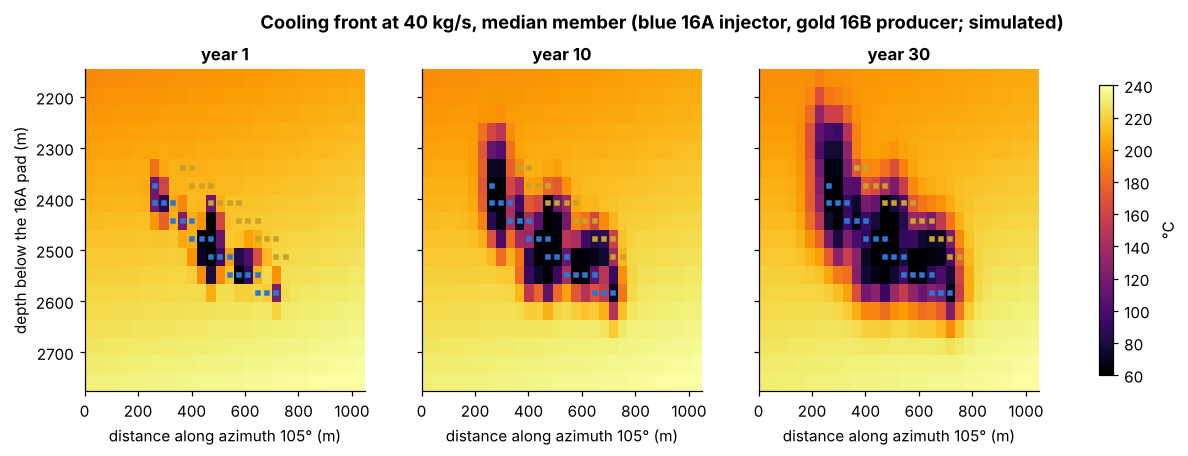

In [6]:
F = np.load("results/forge_pair_fields.npz")
nz_, ny_, nx_ = F["shape"]; h = float(F["cell"])
def sec(Tf):
    Tf = Tf.reshape(nz_, ny_, nx_)
    kA = np.unravel_index(F["well_A"], (nz_, ny_, nx_))
    j = int(np.median(kA[1]))
    return Tf[:, j, :], j
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a_, key, yr in zip(ax, ("T1", "T10", "T30"), (1, 10, 30)):
    s_, j = sec(F[key])
    im = a_.imshow(s_, extent=[0, nx_ * h, float(F["z_top"]) + nz_ * h, float(F["z_top"])], cmap="inferno", vmin=60, vmax=240, aspect="auto")
    for wkey, c in (("well_A", BLUE), ("well_B", GOLD)):
        k, jj, i = np.unravel_index(F[wkey], (nz_, ny_, nx_))
        a_.plot((i + 0.5) * h, float(F["z_top"]) + (k + 0.5) * h, "s", color=c, ms=3)
    a_.set_title(f"year {yr}"); a_.set_xlabel("distance along azimuth 105° (m)")
ax[0].set_ylabel("depth below the 16A pad (m)"); fig.colorbar(im, ax=ax, label="°C", shrink=0.9)
fig.suptitle("Cooling front at 40 kg/s, median member (blue 16A injector, gold 16B producer; simulated)", y=1.02, fontweight="bold")
fig.savefig("figures/forge_cooling_front.png")
r40 = R["40"]["scalars"]
print(f"cooled by more than 10 °C at 40 kg/s: {pct(r40['cooled_volume_10y_mm3'])} Mm³ after 10 years, {pct(r40['cooled_volume_30y_mm3'])} Mm³ after 30 years; "
      f"reach from the injector {pct(r40['cooling_reach_30y_m'], '{:.0f}')} m")

## Published numbers

The numbers quoted in the README and on the case page. The notebook stops if they change.

In [7]:
published = {"10_breakthrough_years_P10": 0.9132, "10_breakthrough_years_P50": 1.777, "10_breakthrough_years_P90": 2.607, "10_T_prod_end_c_P10": 116.4, "10_T_prod_end_c_P50": 130.4, "10_T_prod_end_c_P90": 147.7, "10_power_initial_mw_P10": 6.091, "10_power_initial_mw_P50": 6.428, "10_power_initial_mw_P90": 6.569, "10_power_end_mw_P10": 2.358, "10_power_end_mw_P50": 2.948, "10_power_end_mw_P90": 3.68, "20_breakthrough_years_P10": 0.4341, "20_breakthrough_years_P50": 0.8505, "20_breakthrough_years_P90": 1.27, "20_T_prod_end_c_P10": 99.59, "20_T_prod_end_c_P50": 108.0, "20_T_prod_end_c_P90": 126.0, "20_power_initial_mw_P10": 10.95, "20_power_initial_mw_P50": 12.15, "20_power_initial_mw_P90": 12.58, "20_power_end_mw_P10": 3.303, "20_power_end_mw_P50": 4.01, "20_power_end_mw_P90": 5.523, "40_breakthrough_years_P10": 0.212, "40_breakthrough_years_P50": 0.4047, "40_breakthrough_years_P90": 0.6038, "40_T_prod_end_c_P10": 87.09, "40_T_prod_end_c_P50": 90.84, "40_T_prod_end_c_P90": 107.9, "40_power_initial_mw_P10": 17.83, "40_power_initial_mw_P50": 21.33, "40_power_initial_mw_P90": 23.49, "40_power_end_mw_P10": 4.516, "40_power_end_mw_P50": 5.144, "40_power_end_mw_P90": 8.006, "80_breakthrough_years_P10": 0.1086, "80_breakthrough_years_P50": 0.1965, "80_breakthrough_years_P90": 0.2908, "80_T_prod_end_c_P10": 76.66, "80_T_prod_end_c_P50": 79.47, "80_T_prod_end_c_P90": 94.54, "80_power_initial_mw_P10": 25.85, "80_power_initial_mw_P50": 34.61, "80_power_initial_mw_P90": 41.58, "80_power_end_mw_P10": 5.551, "80_power_end_mw_P50": 6.49, "80_power_end_mw_P90": 11.52, "recovery_P50": 0.9384, "T_bh_P50": 214.0, "bt_converged_10": 1.348, "bt_gci_10": 0.1055, "bt_converged_40": 0.28, "bt_gci_40": 0.04483}
now = {}
for q in ("10", "20", "40", "80"):
    for k in ("breakthrough_years", "T_prod_end_c", "power_initial_mw", "power_end_mw"):
        for p in ("P10", "P50", "P90"):
            now[f"{q}_{k}_{p}"] = R[q]["scalars"][k][p]
now["recovery_P50"] = aug["recovery"]["P50"]; now["T_bh_P50"] = aug["produced_T_bottomhole_c"]["P50"]
for q in ("10", "40"):
    now[f"bt_converged_{q}"] = G["rates"][q]["breakthrough_years"]["converged"]; now[f"bt_gci_{q}"] = G["rates"][q]["breakthrough_years"]["error_abs"]
for k, v in published.items():
    x = now[k]
    if isinstance(v, str) or isinstance(x, str):
        assert x == v, (k, x, v)
    else:
        assert abs(x - v) <= 0.02 * abs(v) + 0.01, (k, x, v)
pathlib.Path("results/nb3_doublet_30_years.json").write_text(json.dumps({"published": now}, indent=1))
print("all published numbers reproduced")

all published numbers reproduced


## What this says, and what it does not

* **The 2024 test, reproduced in part.** Calibrated on the August injection pressure alone, the ensemble predicts the produced rate (24.8 kg/s against 24.5 measured) and the recovery (94 %, P10–P90 91–96 %, against 93 % measured). It does **not** reproduce the produced temperature (bottom hole 214 °C against 190 °C at the wellhead; about 13 °C remain after an estimated 11 °C of wellbore cooling) or the April test (about 8 MPa too little injection pressure).
* **10 kg/s is the only pressure-feasible rate** in every member: the injector stays below the minimum horizontal stress and the producer above saturation. At 20 kg/s and above no member is feasible with today's fracture apertures, because the cooled rock near the injector holds colder, more viscous water and the inter-well pressure difference grows over the years.
* **At 10 kg/s** the produced temperature falls from 214 °C to 130 °C after 30 years (P10–P90 116–148 °C), and the heat power from 6.4 MWth to 2.9 MWth (P10–P90 2.4–3.7). Thermal breakthrough comes early: **1.35 ± 0.11 years** grid-converged for the median member; the ensemble on 35 m cells gives 1.8 years (P10–P90 0.9–2.6), and the 35 m grid overestimates breakthrough by about 25 %, so the converged ensemble range is about 0.7–2.1 years.
* **Why so early.** The open intervals are only 90–108 m apart, and the stimulated fractures that carry the flow are a small volume of rock. Long-lived heat needs a larger, more evenly swept volume: wider well spacing or more stimulated fractures, which is the question for the decision chart of notebook 4.

**Limits.** Equivalent continuum on 35 m cells (diagonal permeability); fixed apertures (no pressure or thermal opening, no new fractures), so the forecasts above about twice the 2024 rate are not pressure-feasible and are what-if numbers; local thermal equilibrium between water and rock in a cell; no wellbore model (bottom-hole temperatures; wellbore cooling only estimated); single-phase water; the near-well flow is represented by Peaceman well indices on 35 m cells (near-well upscaling is phase 4). The calibration uses one test and one number.

*References:* McLennan, J., England, K. and Swearingen, L. (2024). Utah FORGE: Wells 16A(78)-32 and 16B(78)-32 Extended Circulation Test Data. GDR 1683, DOI 10.15121/2475065 · Utah FORGE (2024). Stimulation Pressure and Circulation Data, April 2024. GDR 1611, DOI 10.15121/2371032 · Finnila, A. and Jones, C. (2024). 2024 Discrete Fracture Network Model Data. GDR 1646 · Ramey, H. J. (1962). Wellbore heat transmission. J. Petrol. Technol. 14(4) · Roache, P. J. (1994). Perspective: a method for uniform reporting of grid refinement studies. J. Fluids Eng. 116.